# Imputed consumer fraud probabilities: how they behave

A visual check on the imputation tested in Part C of `fraud_penalty.ipynb`. Nothing here feeds the ranking and no files are written.

**Background.** Consumer fraud scores exist only for 28 Feb 2021 – 27 Feb 2022, and transactions run to 26 Oct 2022. The imputation gives each user-day a fraud probability from how much that user spent that day: for each band of daily spend it takes the spend-weighted average probability over all user-days in the band, counting unscored days as 0. The lookup is fitted on 28 Aug 2021 – 27 Feb 2022, the part of the window where every large day carries a score.

**In every figure:** blue is the supplied (real) scores, red is the imputation.

| Period | Dates | What we have |
|---|---|---|
| Early window | 28 Feb – 27 Aug 2021 | real scores, partial coverage |
| Late window | 28 Aug 2021 – 27 Feb 2022 | real scores, full coverage (the lookup is fitted here) |
| After the window | 28 Feb – 26 Oct 2022 | no scores; imputed only |

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from pyspark.sql import SparkSession, functions as F

# Works when launched from the repository, project2, or notebooks directory.
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if p.name == "project2"), None)
if PROJECT_ROOT is None:
    PROJECT_ROOT = Path.cwd() / "project2"
PROCESSED_PATH = PROJECT_ROOT / "data" / "tables" / "processed"
if not PROCESSED_PATH.is_dir():
    raise FileNotFoundError("Set PROJECT_ROOT to your project2 directory.")
spark = SparkSession.builder.config("spark.driver.memory", "6g").getOrCreate()

START, END = "2021-02-28", "2022-02-27"     # consumer fraud scores exist only in this window
REGIME_START = "2021-08-28"                 # scoring coverage is complete from here
MIN_SCORES = [0, 30]                        # count every score / count only flags (the adopted setting)
BINS_PER_DECADE = 10                        # log-spaced bands of a user's total spend that day
MAX_SPEND_BIN = int(np.floor(np.log10(20_000) * BINS_PER_DECADE))   # pool everything above about $20K

OBS_BLUE, IMP_RED = "#4C78A8", "#d62728"
sns.set_style("whitegrid", {"grid.color": "#ececec"})


def shade_periods(ax, label=True):
    """Shade the three periods: real scores (two blues) and imputed only (red)."""
    spans = [(START, REGIME_START, OBS_BLUE, 0.07, "real scores, partial coverage"),
             (REGIME_START, "2022-02-28", OBS_BLUE, 0.17, "real scores, full coverage"),
             ("2022-02-28", "2022-10-27", IMP_RED, 0.08, "no scores: imputed only")]
    for a, b, colour, alpha, name in spans:
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=colour, alpha=alpha, linewidth=0,
                   label=name if label else None)
    ax.set_xlim(pd.Timestamp(START), pd.Timestamp("2022-10-27"))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/01 18:05:53 WARN Utils: Your hostname, CJpooter, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/10/01 18:05:53 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/cjboi/miniconda3/envs/proj2_bnpl/lib/python3.12/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/10/01 18:05:53 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/10/01 18:05:54 WARN Utils: Service 'SparkU

## 2. User-days and the spend-band lookup

One row per user per day, with that day's total spend and the supplied score where there is one.

In [2]:
def p_if_at_least(score_col, min_score):
    return F.when(F.col(score_col) >= min_score, F.col(score_col) / 100).otherwise(0.0)


consumer_scores = (spark.read.parquet(str(PROCESSED_PATH / "consumer_fraud_probability"))
                   .where(F.col("fraud_probability").isNotNull())
                   .select("user_id", F.to_date("order_datetime").alias("order_date"),
                           F.col("fraud_probability").alias("consumer_score")))
user_days = (
    spark.read.parquet(str(PROCESSED_PATH / "transactions_clean"))
    .withColumn("order_date", F.to_date("order_datetime"))
    .groupBy("user_id", "order_date").agg(F.sum("dollar_value").alias("day_spend"))
    .join(consumer_scores, ["user_id", "order_date"], "left")
    .withColumn("spend_bin", F.least(F.floor(F.log10("day_spend") * BINS_PER_DECADE), F.lit(MAX_SPEND_BIN)))
).cache()


def build_lookup(days):
    """Spend-weighted fraud probability per spend band, over scored and unscored user-days alike."""
    return days.groupBy("spend_bin").agg(
        F.count("*").alias("days"),
        F.avg(F.col("consumer_score").isNotNull().cast("double")).alias("share_scored"),
        F.min("day_spend").alias("spend_from"),
        *[(F.sum(p_if_at_least("consumer_score", m) * F.col("day_spend")) / F.sum("day_spend")).alias(f"p_day_min{m}")
          for m in MIN_SCORES])


late_days = user_days.where(F.col("order_date").between(REGIME_START, END))
early_days = user_days.where((F.col("order_date") >= START) & (F.col("order_date") < REGIME_START))
lookup = build_lookup(late_days).cache()                    # the one used for the imputation
lookup_late = lookup.toPandas().sort_values("spend_bin")
lookup_early = build_lookup(early_days).toPandas().sort_values("spend_bin")   # for comparison only
print(f"{user_days.count():,} user-days; lookup has {len(lookup_late)} spend bands")

/home/cjboi/miniconda3/envs/proj2_bnpl/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/cjboi/miniconda3/envs/proj2_bnpl/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


8,976,957 user-days; lookup has 81 spend bands


## 3. What the lookup looks like

The imputation is this curve. Both regimes are drawn so the difference between them is visible; only the later one is used.

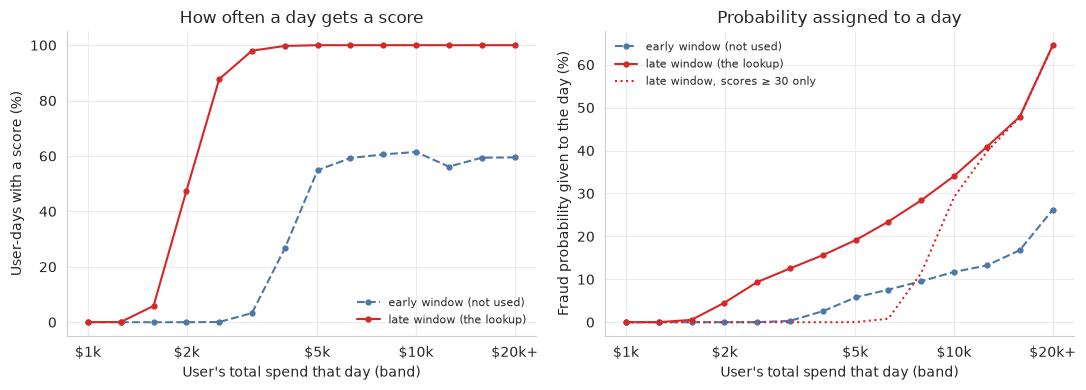

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for frame, colour, style, name in [(lookup_early, OBS_BLUE, "--", "early window (not used)"),
                                   (lookup_late, IMP_RED, "-", "late window (the lookup)")]:
    part = frame[frame["spend_from"] >= 800]
    axes[0].plot(part["spend_from"], part["share_scored"] * 100, color=colour, linestyle=style,
                 marker="o", markersize=3.5, linewidth=1.5, label=name)
    axes[1].plot(part["spend_from"], part["p_day_min0"] * 100, color=colour, linestyle=style,
                 marker="o", markersize=3.5, linewidth=1.5, label=name)
axes[1].plot(lookup_late.loc[lookup_late["spend_from"] >= 800, "spend_from"],
             lookup_late.loc[lookup_late["spend_from"] >= 800, "p_day_min30"] * 100,
             color=IMP_RED, linestyle=":", linewidth=1.5, label="late window, scores ≥ 30 only")
for ax, title, ylabel in [(axes[0], "How often a day gets a score", "User-days with a score (%)"),
                          (axes[1], "Probability assigned to a day", "Fraud probability given to the day (%)")]:
    ax.set_xscale("log")
    ax.set_xticks([1000, 2000, 5000, 10000, 20000], ["$1k", "$2k", "$5k", "$10k", "$20k+"])
    ax.minorticks_off()
    ax.set(xlabel="User's total spend that day (band)", ylabel=ylabel, title=title)
    ax.legend(frameon=False, fontsize=8)
    sns.despine(ax=ax)
fig.tight_layout()
plt.show()

## 4. Through time: real scores against the imputation

Expected fraud loss per \$100 transacted, as a 7-day rolling figure. The imputed line is drawn across the **whole** dataset, including the months that have real scores, so the two can be compared directly where both exist.

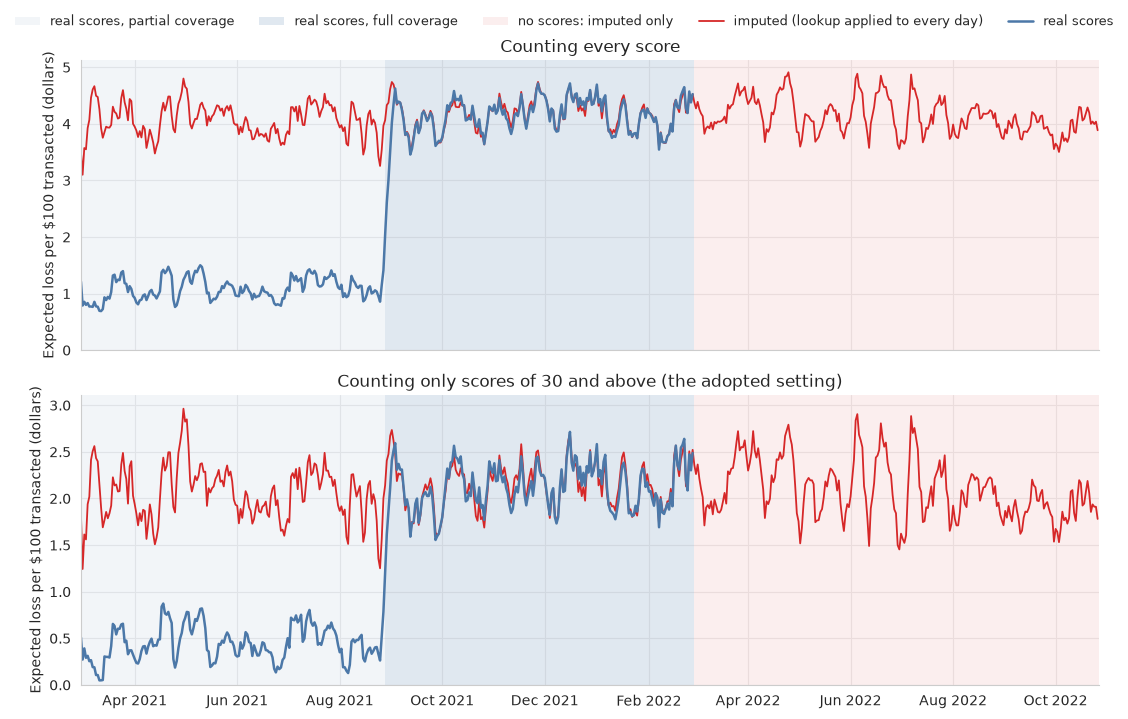

In [4]:
daily = (
    user_days.join(F.broadcast(lookup.select("spend_bin", "share_scored", *[f"p_day_min{m}" for m in MIN_SCORES])),
                   "spend_bin", "left")
    .groupBy("order_date")
    .agg(F.sum("day_spend").alias("value"),
         F.sum(F.col("consumer_score").isNotNull().cast("int")).alias("scored_days"),
         F.sum(F.coalesce("share_scored", F.lit(0.0))).alias("expected_scored_days"),
         *[F.sum(p_if_at_least("consumer_score", m) * F.col("day_spend")).alias(f"observed_loss_min{m}")
           for m in MIN_SCORES],
         *[F.sum(F.coalesce(F.col(f"p_day_min{m}"), F.lit(0.0)) * F.col("day_spend")).alias(f"imputed_loss_min{m}")
           for m in MIN_SCORES])
    .toPandas()
)
daily["order_date"] = pd.to_datetime(daily["order_date"])
daily = daily.sort_values("order_date").set_index("order_date")
in_window = (daily.index >= START) & (daily.index <= END)

rolling = daily.rolling("7D").sum()
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for ax, m, title in [(axes[0], 0, "Counting every score"),
                     (axes[1], 30, "Counting only scores of 30 and above (the adopted setting)")]:
    observed = (rolling[f"observed_loss_min{m}"] / rolling["value"] * 100).where(in_window)
    imputed = rolling[f"imputed_loss_min{m}"] / rolling["value"] * 100
    shade_periods(ax, label=(m == 0))
    ax.plot(imputed.index, imputed, color=IMP_RED, linewidth=1.3, label="imputed (lookup applied to every day)")
    ax.plot(observed.index, observed, color=OBS_BLUE, linewidth=1.8, label="real scores")
    ax.set(ylabel="Expected loss per \$100 transacted (dollars)", title=title)
    ax.set_ylim(0, None)
    sns.despine(ax=ax)
fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, fontsize=9, ncol=5,
           loc="upper center", bbox_to_anchor=(0.5, 1.03))
fig.tight_layout()
plt.show()

## 5. What the imputation adds, month by month

Expected loss in dollars. Blue is what the real scores give. Solid red is the imputed loss after the window (Test A in `fraud_penalty.ipynb`). Hatched red is the extra loss if the under-scored early months are re-priced from the lookup as well (Test B).

MIN_SCORE  0: real $38.3M | imputed after the window $41.2M | early top-up $18.0M
MIN_SCORE 30: real $19.0M | imputed after the window $20.8M | early top-up $9.7M


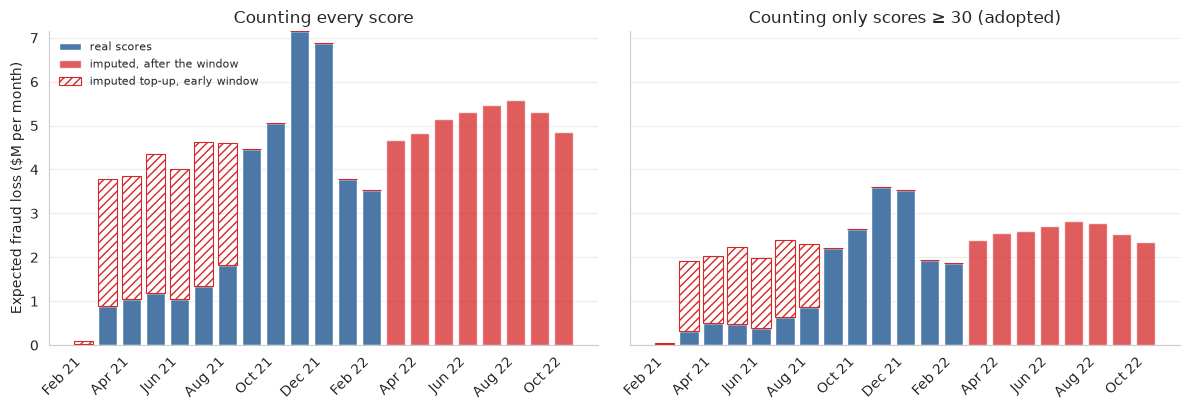

In [5]:
monthly = daily.resample("MS").sum()
early = monthly.index < pd.Timestamp("2021-09-01")
after = monthly.index >= pd.Timestamp("2022-03-01")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, m, title in [(axes[0], 0, "Counting every score"), (axes[1], 30, "Counting only scores ≥ 30 (adopted)")]:
    observed = monthly[f"observed_loss_min{m}"] / 1e6
    imputed = monthly[f"imputed_loss_min{m}"] / 1e6
    added_after = imputed.where(after, 0.0)
    # February 2022 holds one day after the window (the 28th), so top it up to the imputed level as well.
    top_up_early = (imputed - observed).clip(lower=0).where(early, 0.0)
    x = np.arange(len(monthly))
    ax.bar(x, observed, color=OBS_BLUE, width=0.8, label="real scores")
    ax.bar(x, added_after, bottom=observed, color=IMP_RED, alpha=0.75, width=0.8, label="imputed, after the window")
    ax.bar(x, top_up_early, bottom=observed, facecolor="none", edgecolor=IMP_RED, hatch="////", linewidth=0.8,
           width=0.8, label="imputed top-up, early window")
    ax.set_xticks(x[::2], [d.strftime("%b %y") for d in monthly.index[::2]], rotation=45, ha="right")
    ax.set(title=title, xlabel="")
    ax.grid(axis="x", visible=False)
    sns.despine(ax=ax)
    print(f"MIN_SCORE {m:>2}: real ${observed.sum():.1f}M | imputed after the window ${added_after.sum():.1f}M | "
          f"early top-up ${top_up_early.sum():.1f}M")
axes[0].set_ylabel("Expected fraud loss ($M per month)")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

## 6. Real scores are per day; imputed values are band averages

A real score is specific to one user-day and can be anywhere from 8 to 99. An imputed value is the average for a spend band, so every day in a band gets the same number and extremes disappear. The comparison below uses user-days that spent \$2,000 or more.

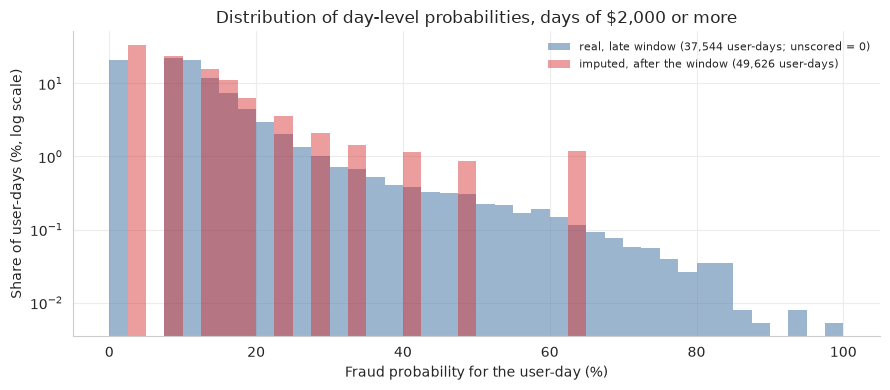

mean probability: real 0.121, imputed 0.122
largest value   : real 0.99, imputed 0.65


In [6]:
MIN_SPEND = 2000
real = (late_days.where((F.col("day_spend") >= MIN_SPEND))
        .select((F.coalesce("consumer_score", F.lit(0.0)) / 100).alias("p")).toPandas()["p"])
imputed_p = (user_days.where((F.col("order_date") > END) & (F.col("day_spend") >= MIN_SPEND))
             .join(F.broadcast(lookup.select("spend_bin", "p_day_min0")), "spend_bin", "left")
             .select(F.coalesce("p_day_min0", F.lit(0.0)).alias("p")).toPandas()["p"])

bins = np.arange(0, 1.0001, 0.025)
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(x=real * 100, bins=bins * 100, stat="percent", color=OBS_BLUE, alpha=0.55, edgecolor="none",
             label=f"real, late window ({len(real):,} user-days; unscored = 0)", ax=ax)
sns.histplot(x=imputed_p * 100, bins=bins * 100, stat="percent", color=IMP_RED, alpha=0.45, edgecolor="none",
             label=f"imputed, after the window ({len(imputed_p):,} user-days)", ax=ax)
ax.set_yscale("log")
ax.set(xlabel="Fraud probability for the user-day (%)", ylabel="Share of user-days (%, log scale)",
       title=f"Distribution of day-level probabilities, days of ${MIN_SPEND:,} or more")
ax.legend(frameon=False, fontsize=8)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()
print(f"mean probability: real {real.mean():.3f}, imputed {imputed_p.mean():.3f}")
print(f"largest value   : real {real.max():.2f}, imputed {imputed_p.max():.2f}")

## Reading the plots

- **§3.** In the late window a user-day is almost never scored below about \$1,500, about half are scored at \$2,000, and every day above about \$3,000 is. In the early window the same curve tops out near 60%, and the probabilities are roughly a third as large. The imputation uses the late-window curve.
- **§4.** Where real scores have full coverage (darker blue band), the imputed line sits on top of the real one, including its week-to-week movement. That is the evidence that daily spend is enough to reproduce the scores in aggregate. In the early window the real line drops to about a quarter of the imputed one on the same day the data snapshot changes, with no matching change in spending. After the window, the imputed line carries on at the late-window level, because spending patterns carry on.
- **§5.** The imputation adds roughly as much loss after the window as the real scores record inside it, and re-pricing the early months adds about half as much again. These totals cover every merchant in the transactions, including the 396 with no metadata, so they are higher than the ranked-merchant totals in `fraud_penalty.ipynb`.
- **§6.** Imputed values are band averages: they match the real scores on average (mean 0.12 for both) but come in a handful of fixed levels and never exceed 0.65, where real scores reach 0.99. So the imputation is sound for totals and for a merchant's overall exposure, and should not be read as a statement about any single transaction.

**What the plots cannot show.** Whether scoring after February 2022 really followed the late-window pattern. The imputation assumes it did; the one regime change visible in §4 is a reminder that it might not have.